In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import time

In [15]:
(x_train, y_train), (x_test, y_test) = (
    (np.fromfile('MNIST/train-images-idx3-ubyte', np.uint8)[16:].reshape(-1,28,28),
     np.fromfile('MNIST/train-labels-idx1-ubyte', np.uint8)[8:]),
    (np.fromfile('MNIST/t10k-images-idx3-ubyte', np.uint8)[16:].reshape(-1,28,28),
     np.fromfile('MNIST/t10k-labels-idx1-ubyte', np.uint8)[8:])
)

In [16]:
x_train = x_train.reshape(-1,784).astype('float32') / 255.0
x_test = x_test.reshape(-1,784).astype('float32') / 255.0

y_train = tf.keras.utils.to_categorical(y_train,10)
y_test = tf.keras.utils.to_categorical(y_test,10)

In [17]:
activations = ['sigmoid', 'tanh', 'relu']

accuracies = []
times = []

In [18]:
for act in activations:

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),
        tf.keras.layers.Dense(128, activation=act),
        tf.keras.layers.Dense(64, activation=act),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    start = time.time()

    model.fit(x_train, y_train, epochs=3, batch_size=64, verbose=1)

    times.append(time.time() - start)

    loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

    accuracies.append(accuracy)

    print(act, "Accuracy:", accuracy)

Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8507 - loss: 0.6082
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9370 - loss: 0.2192
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9533 - loss: 0.1585
sigmoid Accuracy: 0.9567000269889832
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.9166 - loss: 0.2920
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9600 - loss: 0.1346
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9717 - loss: 0.0934
tanh Accuracy: 0.9693999886512756
Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.9169 - loss: 0.2849
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9649 - loss: 0.1154
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9765 - loss: 0.0777
relu Accuracy: 0.970300018787384


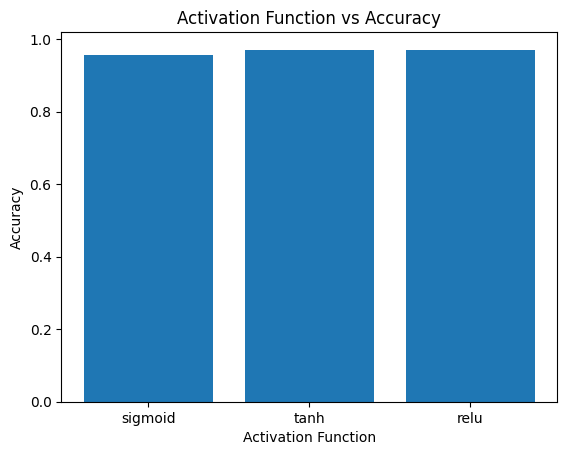

In [19]:
plt.bar(activations, accuracies)
plt.title("Activation Function vs Accuracy")
plt.xlabel("Activation Function")
plt.ylabel("Accuracy")
plt.show()

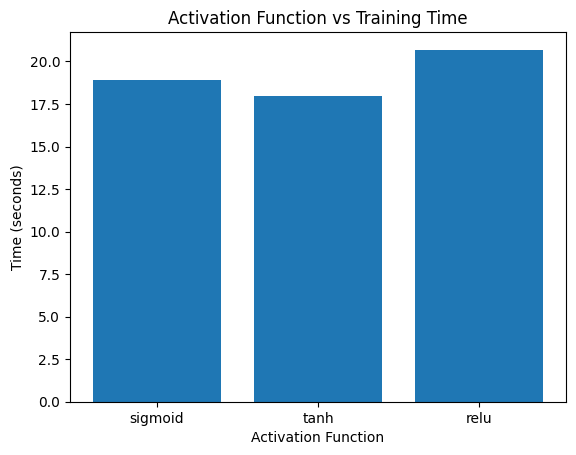

In [20]:
plt.bar(activations, times)
plt.title("Activation Function vs Training Time")
plt.xlabel("Activation Function")
plt.ylabel("Time (seconds)")
plt.show()

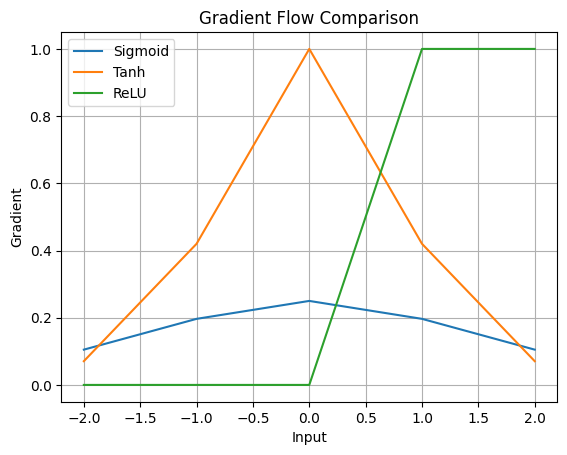

In [21]:
x = tf.constant([-2., -1., 0., 1., 2.])

s = tf.sigmoid(x)
t = tf.tanh(x)

plt.plot(x, s * (1-s), label='Sigmoid')
plt.plot(x, 1-t**2, label='Tanh')
plt.plot(x, tf.cast(x > 0, tf.float32), label='ReLU')

plt.title("Gradient Flow Comparison")
plt.xlabel("Input")
plt.ylabel("Gradient")
plt.legend()
plt.grid()
plt.show()

In [22]:
data = np.load('mnist.npz')

x_train = data['x_train']
y_train = data['y_train']

x_test = data['x_test']
y_test = data['y_test']